<a href="https://colab.research.google.com/github/dkumar-tech/desktop-tutorial/blob/main/KG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title
!pip install rdflib networkx matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 kB 10.8 MB/s eta 0:00:00


In [2]:
import pandas as pd
data = pd.DataFrame([
["Site01","contains","Cell001"],
["Cell001","uses","Transport001"],
["Transport001","connectsTo","UPF001"],
["UPF001","supports","VoNR_Service"],
["VoNR_Service","serves","Customer001"],
["Customer001","hasSLA","Gold_SLA"]
])
data.columns=["subject","predicate","object"]

data

,subject,predicate,object
0,Site01,contains,Cell001
1,Cell001,uses,Transport001
2,Transport001,connectsTo,UPF001
3,UPF001,supports,VoNR_Service
4,VoNR_Service,serves,Customer001
5,Customer001,hasSLA,Gold_SLA


In [4]:
from rdflib import Graph, URIRef, Namespace
g = Graph()
TELCO = Namespace("http://telco.com/")
for _, row in data.iterrows():
  s = URIRef(TELCO + row["subject"])
  p = URIRef(TELCO + row["predicate"])
  o = URIRef(TELCO + row["object"])
  g.add((s,p,o))
print("Triples:",len(g))

Triples: 6


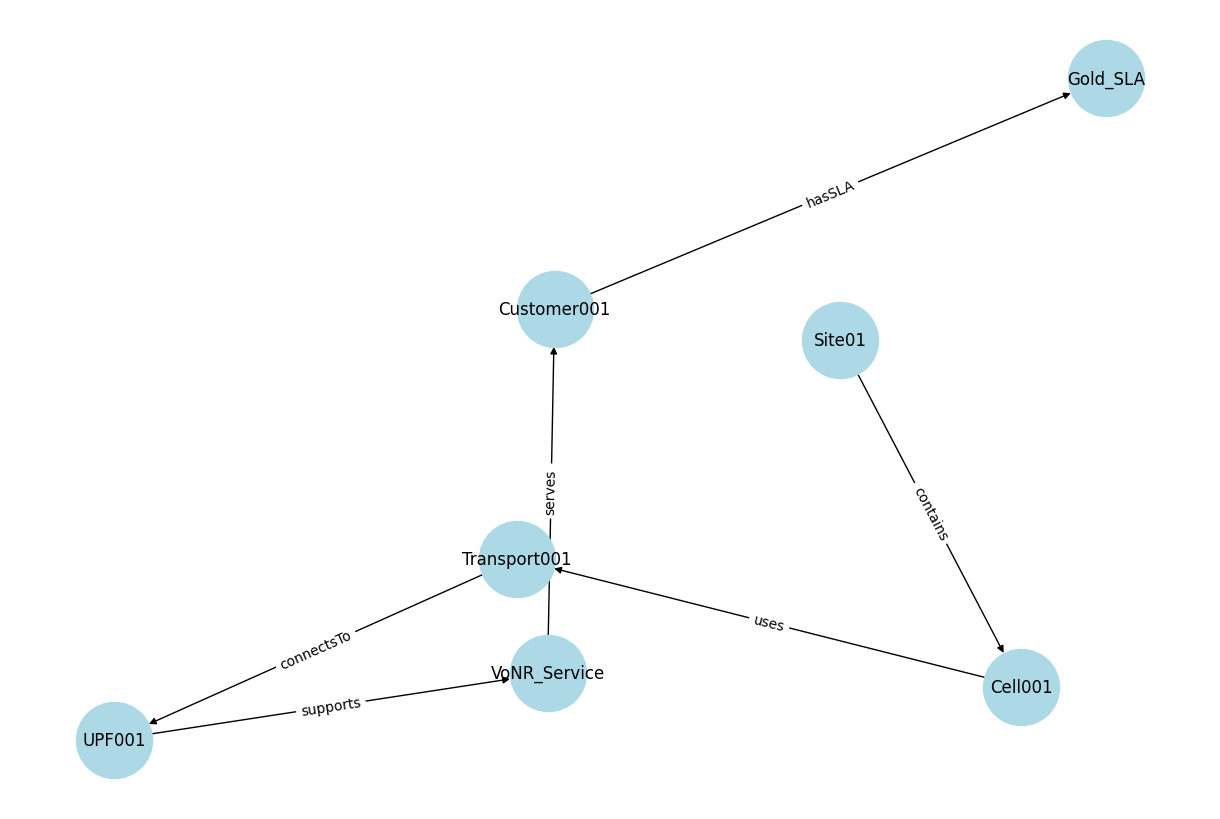

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
G = nx.DiGraph()
for s,p,o in g:
  G.add_edge(
    s.split("/")[-1],
    o.split("/")[-1],
    label=p.split("/")[-1]
)
plt.figure(figsize=(12,8))
pos = nx.spring_layout(G,k=1)
nx.draw(
G,
pos,
with_labels=True,
node_size=3000,
node_color="lightblue"
)
edge_labels = nx.get_edge_attributes(
G,
'label'
)
nx.draw_networkx_edge_labels(
G,
pos,
edge_labels=edge_labels
)
plt.show()

In [7]:
from rdflib.namespace import RDF,RDFS
g.add((TELCO.Site,RDF.type,RDFS.Class))
g.add((TELCO.Cell,RDF.type,RDFS.Class))
g.add((TELCO.Transport,RDF.type,RDFS.Class))
g.add((TELCO.UPF,RDF.type,RDFS.Class))
g.add((TELCO.Customer,RDF.type,RDFS.Class))
g.add((TELCO.Site01,RDF.type,TELCO.Site))
g.add((TELCO.Cell001,RDF.type,TELCO.Cell))

<Graph identifier=N3a0c30edebe14e5c846689466ec47135 (<class 'rdflib.graph.Graph'>)>

In [10]:
query = """
  SELECT ?customer
    WHERE {

  ?cell <http://telco.com/uses> ?transport .
  ?transport <http://telco.com/connectsTo> ?upf .
  ?upf <http://telco.com/supports> ?service .
  ?service <http://telco.com/serves> ?customer .
 }
"""
for row in g.query(query):
  print(row)

ParseException: Expected SelectQuery, found '\xa0'  (at char 30), (line:4, col:1)